# 05 · Transient snapshots: how does the capture zone change through the seasons?

Recharge is high in the wet season and nearly zero in the dry season. A supply well usually pumps most in the dry season. The capture zone of tutorial 01 is for one steady flow field. In a transient model the flow field changes from one time step to the next, and so does the zone.

This tutorial traces every time step of a seasonal model as a **snapshot** and combines the snapshots into maps that summarise the seasons. You will:

1. build a three-year transient version of the tutorial aquifer, with seasonal recharge and pumping;
2. learn what the **snapshot** (time-instant steady-state) assumption means and where it stops being valid;
3. map the capture zone in each season;
4. follow the well's water by source (recharge, storage, stream, west edge) through the seasons;
5. summarise all time steps with `gs.trace_transient`: min, max and mean $F$, always/sometimes/never maps, exceedance counts and the probability that a cell carries more than 1 m³/d of the well's water;
6. see when **time weighting** and **equal weighting** of the steps give different answers;
7. see one way to combine the maps into nested zones.

**Runtime:** about 10 seconds (the last code cell prints the measured time). **Prerequisites:** tutorial 01.

## Settings

All settings live in this first cell. The model workspace goes to `tutorials/_work/05_transient_snapshots/` (git-ignored, recreated on every run). The model builders and plotting helpers are in [`tutorials/herebedragons.py`](../herebedragons.py).

In [1]:
import sys
import time
from pathlib import Path

import flopy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.colors import BoundaryNorm, ListedColormap

sys.path.insert(0, str(Path.cwd().parent))  # tutorials/ holds the shared helpers
import herebedragons as hbd  # noqa: E402

import gwsource as gs  # noqa: E402

START = time.perf_counter()  # the notebook prints its run time at the end
WORK = hbd.work_dir("05_transient_snapshots", clean=True)  # tutorials/_work/... (git-ignored)
MF6 = hbd.mf6_exe()  # <repo>/bin/mf6
WELL = "supply_well"  # boundname of the well we trace
N_YEARS = 3  # simulated years after the 1-day steady start
STEPS_PER_SEASON = 3  # time steps per seasonal stress period
SEASONAL_PERIODS = list(range(1, 4 * N_YEARS + 1))  # stress periods analysed (not the steady start)
F_CAPTURE = 0.5  # capture zone: F > F_CAPTURE (always/sometimes/never, exceedance count)
F_OUTLINE = 0.1  # conservative outline: F > F_OUTLINE
VOLUME_LIMIT = 1.0  # m3/d: probability that a cell's volume through exceeds this
SOURCES = {  # label: source packages of the well's water
    "recharge": ("RCH",), "storage": ("STO-SS", "STO-SY"), "stream": ("SFR",), "west edge": ("CHD",),
}
SOURCE_COLOURS = {"recharge": "tab:green", "storage": "tab:orange", "stream": "tab:blue", "west edge": "0.55"}

plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.0, 5.5)})
print(f"gwsource {gs.__version__}, FloPy {flopy.__version__}")

gwsource 0.0.1, FloPy 3.12.0.dev0


## 1. Build and run the transient model

`hbd.build_transient` adds storage to the tutorial aquifer (specific yield 0.2, specific storage 1e-5 /m) and runs it for a 1-day steady stress period followed by three years of four seasons, three time steps of about 30 days per season: 37 time steps in all. Recharge and pumping change with the season (multipliers of the tutorial 01 values, 0.5 mm/d and 800 m³/d):

In [2]:
run = hbd.build_transient(WORK / "model", MF6, n_years=N_YEARS, steps_per_season=STEPS_PER_SEASON)
info = run.info
seasons = pd.DataFrame(
    {"recharge factor": info["recharge_factor"][1:5], "pumping factor": info["pumping_factor"][1:5]},
    index=info["season"][1:5],
)
seasons["recharge (mm/yr)"] = seasons["recharge factor"] * run.spec.rech * 1000 * 365.25
seasons["pumping (m3/d)"] = -seasons["pumping factor"] * run.spec.wells[0][2]
display(seasons.round(2))

reader = gs.open_model(run.ws, boundnames=True)  # grid and budget files opened once
print(f"{len(reader.steps)} saved time steps; first: {reader.steps[:4]}")
print("step lengths (d):", sorted({round(reader.step_length(ks), 2) for ks in reader.steps}))

,recharge factor,pumping factor,recharge (mm/yr),pumping (m3/d)
wet,1.8,0.8,328.72,640.0
wet-to-dry,1.0,1.0,182.62,800.0
dry,0.1,1.4,18.26,1120.0
dry-to-wet,1.1,0.8,200.89,640.0


37 saved time steps; first: [(0, 0), (0, 1), (1, 1), (2, 1)]
step lengths (d): [1.0, 30.44]


`gs.open_model` returns a `StepReader`: it reads the grid once and then any saved time step with `reader.read((kstp, kper))`. The time steps are 0-based `(kstp, kper)` pairs, as in FloPy.

## 2. The snapshot assumption

`gwsource` traces a transient model one time step at a time. Each step's flows are treated **as if they were steady**: the capture zone of a step is the zone the well would have if that step's recharge, pumping and storage flows lasted forever. Storage enters the budget like any other external term:

- when the water table **falls**, water released from storage (STO-SY, and STO-SS from compression) enters the cell as a **source**;
- when the water table **rises**, water going into storage leaves the flow as a **sink**, competing with the well like a weak sink.

This is the approach of the reference method (Foley & Black 2013), and it answers a useful question: *how does the steady capture zone move as conditions change?* It has two limits that are worth keeping in mind:

1. **No travel lag.** Water takes years to cross the capture zone (tutorial 06), while a season lasts three months. The dry-season snapshot is not where the water pumped in the dry season came from. It is where that water *would* come from if the dry season lasted.
2. **Storage hides the true source.** Water released from storage in the dry season is old recharge (or stream water) that went into storage in an earlier, wetter season. A snapshot can only say "storage". In the same way, water that goes into storage in the wet season counts as lost to the well, even if it flows to the well in the next dry season.

Tutorial 08 tracks water through storage from step to step and removes both limits, at the cost of needing porosity and running through every step in order. The snapshots here are cheap, need nothing beyond the budget file, and are the standard way to show seasonal variability.

## 3. The capture zone in each season

The middle time step of each season of the last year:

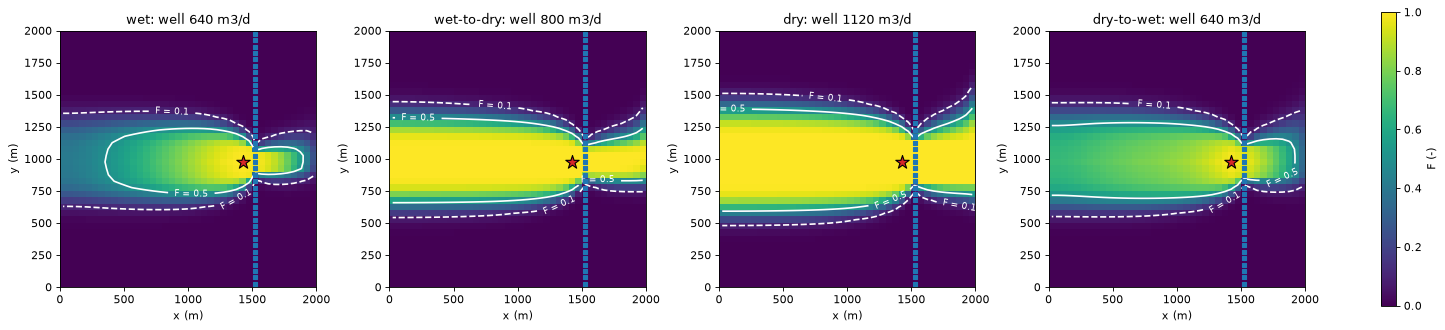

,well (m3/d),max F,area F > 0.1 (km2),area F > 0.5 (km2),west end x (m),north side y (m),south side y (m)
last year,,,,,,,
wet,640.0,0.999,1.245,0.580,375.0,1225.0,775.0
wet-to-dry,800.0,1.000,1.475,1.062,25.0,1275.0,675.0
dry,1120.0,1.000,1.752,1.360,25.0,1375.0,625.0
dry-to-wet,640.0,0.996,1.495,0.948,25.0,1275.0,725.0


well cell centre at x = 1425 m
dry - wet: west end -350 m, north side +150 m, south side -150 m


In [3]:
last_year = [(1, kper) for kper in SEASONAL_PERIODS[-4:]]  # middle step of each season
centres = gs.export.cell_centres(run.grb_file)
season_rows = {}
fig, axes = plt.subplots(1, 4, figsize=(18.0, 4.4), layout="constrained")
for ax, kstpkper in zip(axes, last_year):
    step = reader.read(kstpkper)
    res = gs.backward(step, {WELL: gs.select(step, boundnames=[WELL])})
    F = res.fraction_through[WELL]
    hbd.plot_cells(
        run.grb_file, step, F, ax=ax, cmap="viridis", vmin=0.0, vmax=1.0, overlay=False,
        colorbar=False,
        title=f"{info['season'][kstpkper[1]]}: well {res.destination_inflow[WELL]:.0f} m3/d",
    )
    hbd.add_contours(ax, run.grb_file, step, F, (F_OUTLINE, F_CAPTURE), colors="w", linestyles=["--", "-"])
    hbd.overlay_features(ax, run.grb_file, step, packages=("SFR", "WEL"), legend=False)
    stream_x = centres[hbd.feature_cells(step, "SFR"), 0].min()
    zone = (F > F_CAPTURE) & (centres[:, 0] < stream_x)  # the F > 0.5 zone west of the stream
    season_rows[info["season"][kstpkper[1]]] = {
        "well (m3/d)": res.destination_inflow[WELL], "max F": F.max(),
        f"area F > {F_OUTLINE} (km2)": step.area[F > F_OUTLINE].sum() / 1e6,
        f"area F > {F_CAPTURE} (km2)": step.area[F > F_CAPTURE].sum() / 1e6,
        "west end x (m)": centres[zone, 0].min(), "north side y (m)": centres[zone, 1].max(),
        "south side y (m)": centres[zone, 1].min(),
    }
fig.colorbar(axes[0].collections[0], ax=axes, shrink=0.85, label="F (-)")
plt.show()
season_table = pd.DataFrame(season_rows).T
display(season_table.round(3).rename_axis("last year"))
change = season_table.loc["dry"] - season_table.loc["wet"]
print(f"well cell centre at x = {centres[np.flatnonzero(res.selections[WELL].cells)[0], 0]:.0f} m")
print(f"dry - wet: west end {change['west end x (m)']:+.0f} m, north side {change['north side y (m)']:+.0f} m, "
      f"south side {change['south side y (m)']:+.0f} m")

The table under the maps describes the middle step of each season of the last year. It gives the well's pumping, the largest $F$, and the areas with $F > 0.1$ and $F > 0.5$. The last three columns locate the $F > 0.5$ zone west of the stream by cell-centre coordinates: its westmost cell, its northmost cell and its southmost cell.

The zone is smallest in the **wet season**, at both thresholds. In the wet season the well pumps least, recharge is highest, and the rising water table puts water into storage. Storage is then a sink that takes a share of the water passing through each cell. The $F > 0.5$ zone ends about 1 km west of the well (westmost cell centre at x = 375 m, well cell at x = 1425 m) instead of reaching the west edge. In the **dry season** the well pumps most and recharge nearly stops. The zone widens until the pumping is balanced by water from storage, from the stream and from the west edge. Between the wet and the dry season the western end of the $F > 0.5$ zone moves 350 m, to the cells on the west edge. Its north and south sides each move out by 150 m.

## 4. The well's water by source, season by season

To see what feeds the well in each step, trace every step and sum the volume from by source package. `gs.trace_transient` (section 5) keeps per-cell statistics, not these per-step totals, so this is a plain loop over the steps. It is also what `trace_transient` does inside. The loop keeps each step's $F$ for the sanity check at the end.

In [4]:
rows, f_series = [], {}
for kstpkper in reader.steps:
    step = reader.read(kstpkper)
    res = gs.backward(step, {WELL: gs.select(step, boundnames=[WELL])})
    by_package = {name: v.sum() for name, v in res.volume_from_by_term[WELL].items()}
    row = {label: sum(by_package.get(p, 0.0) for p in packages) for label, packages in SOURCES.items()}
    assert set(by_package) <= {p for packages in SOURCES.values() for p in packages}
    row.update({
        "end (d)": step.totim, "length (d)": step.notes["delt"], "season": info["season"][kstpkper[1]],
        "pumping": res.destination_inflow[WELL], "solver": res.solver_used[0],
    })
    rows.append(row)
    f_series[kstpkper] = res.fraction_through[WELL]
by_step = pd.DataFrame(rows)
print("solvers used:", set(by_step["solver"]), "| largest |sum of sources - pumping|:",
      f"{(by_step[list(SOURCES)].sum(axis=1) - by_step['pumping']).abs().max():.1e} m3/d")

solvers used: {'topological'} | largest |sum of sources - pumping|: 4.0e-07 m3/d


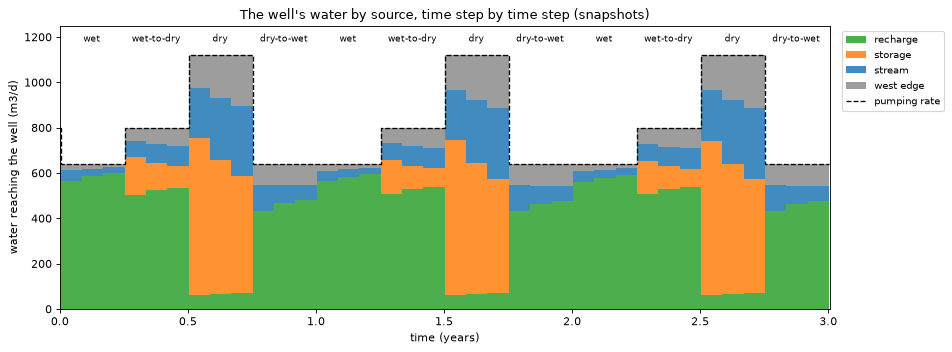

,recharge,storage,stream,west edge
mean share by season,,,,
wet,0.907,0.000,0.057,0.036
wet-to-dry,0.655,0.145,0.103,0.097
dry,0.059,0.528,0.242,0.172
dry-to-wet,0.716,0.000,0.136,0.148


In [5]:
start = (by_step["end (d)"] - by_step["length (d)"]).to_numpy()
x = np.column_stack([start, by_step["end (d)"]]).ravel() / 365.25  # step edges, in years
stack = [np.repeat(by_step[label].to_numpy(), 2) for label in SOURCES]

fig, ax = plt.subplots(figsize=(12.0, 4.5))
ax.stackplot(x, *stack, labels=list(SOURCES), colors=list(SOURCE_COLOURS.values()), alpha=0.85)
ax.plot(x, np.repeat(by_step["pumping"].to_numpy(), 2), color="k", lw=1.2, ls="--", label="pumping rate")
for year in range(N_YEARS):
    for k, season in enumerate(hbd.SEASONS):
        ax.text(year + (k + 0.5) / 4, 1180, season, ha="center", fontsize=8)
ax.set_xlim(0.0, N_YEARS + 0.005)
ax.set_ylim(0.0, 1250.0)
ax.set_xlabel("time (years)")
ax.set_ylabel("water reaching the well (m3/d)")
ax.set_title("The well's water by source, time step by time step (snapshots)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=9)
fig.tight_layout()
plt.show()

shares = by_step[by_step["season"] != "steady"].groupby("season", sort=False)[list(SOURCES)].mean()
display((shares.div(shares.sum(axis=1), axis=0)).round(3).rename_axis("mean share by season"))

In [6]:
seasonal = by_step[by_step["season"] != "steady"].reset_index(drop=True)  # 36 steps, year by year
f_seasonal = np.array([f_series[ks] for ks in reader.steps if ks != (0, 0)])
per_year = len(seasonal) // N_YEARS
for year in range(1, N_YEARS):
    now, before = slice(year * per_year, (year + 1) * per_year), slice((year - 1) * per_year, year * per_year)
    d_source = np.abs(seasonal[list(SOURCES)].to_numpy()[now] - seasonal[list(SOURCES)].to_numpy()[before]).max()
    d_f = np.abs(f_seasonal[now] - f_seasonal[before]).max()
    print(f"year {year + 1} vs year {year}, step by step: largest change in a source's volume {d_source:5.2f} m3/d, "
          f"largest change in F {d_f:.3f}")

year 2 vs year 1, step by step: largest change in a source's volume 17.24 m3/d, largest change in F 0.070
year 3 vs year 2, step by step: largest change in a source's volume  4.50 m3/d, largest change in F 0.014


Each band is one source's contribution, and together they add up to the pumping rate (dashed line) in every step: the closure of tutorial 01 holds snapshot by snapshot.

- **Wet season and dry-to-wet transition:** the water table is rising, so storage is a sink, not a source. The well's water is about 90 % recharge in the wet season. In the dry-to-wet transition the zone is wider than in the wet season. Recharge supplies about 70 %. The rest comes from the stream and the west edge.
- **Wet-to-dry transition:** the water table starts to fall. Storage begins to supply water.
- **Dry season:** recharge nearly stops. **Storage release supplies more than half** of the pumped water. More comes from the stream and the west edge as the zone widens towards both.

The storage band is the clearest example of limit 2 in section 2. In the dry season more than half of the pumped water is labelled "storage". That water entered the aquifer earlier, in wetter seasons.

The last code cell above compares each year with the year before, step by step. From year 1 to year 2 a source's volume changes by up to 17 m³/d, and $F$ by up to 0.07. From year 2 to year 3 the largest changes are 4.5 m³/d and 0.014. The model is close to a periodic state after the first year. Section 3 maps the last year.

## 5. Statistics over time steps

`gs.trace_transient(reader, groups, mode, config)` traces every selected step and folds each result into running statistics, so memory does not grow with the number of steps. The groups are given as `select()` arguments and re-selected on every step (the term list can change between stress periods). `gs.TransientConfig` sets which steps and outputs to summarise and the test statistics:

| Statistic | Meaning (per cell) |
|---|---|
| `min`, `max`, `mean` | over the steps; the mean is weighted (section 6) |
| `asn` | **a**lways (1), **s**ometimes (0.5) or **n**ever (0) above `threshold` |
| `exceedance_count` | number of steps above `threshold` |
| `probability_in_range` | weighted share of the steps with `low <= value <= high` (`value_range`) |

The threshold and range apply to one output, `test_output` (by default the first of `outputs`). We analyse the 36 seasonal steps and leave out the 1-day steady start, which is model spin-up rather than a season.

In [7]:
groups = {WELL: {"boundnames": [WELL]}}
config = gs.TransientConfig(
    steps=SEASONAL_PERIODS, outputs=("fraction_through", "volume_through"), threshold=F_CAPTURE,
)
stats = gs.trace_transient(reader, groups, "backward", config)
print(f"{len(stats.steps)} steps, {stats.totim[0]:.1f} to {stats.totim[-1]:.1f} d; "
      f"solvers {set(stats.solver_used)}; flow cycles in any step: {stats.n_cycles.max()}")
print("statistics:", {name: list(by_output) for name, by_output in stats.stats.items()})
F_min, F_max, F_mean = (stats.stats[s]["fraction_through"][WELL] for s in ("min", "max", "mean"))

36 steps, 31.4 to 1096.8 d; solvers {'topological'}; flow cycles in any step: 0
statistics: {'min': ['fraction_through', 'volume_through'], 'max': ['fraction_through', 'volume_through'], 'mean': ['fraction_through', 'volume_through'], 'asn': ['fraction_through'], 'exceedance_count': ['fraction_through']}


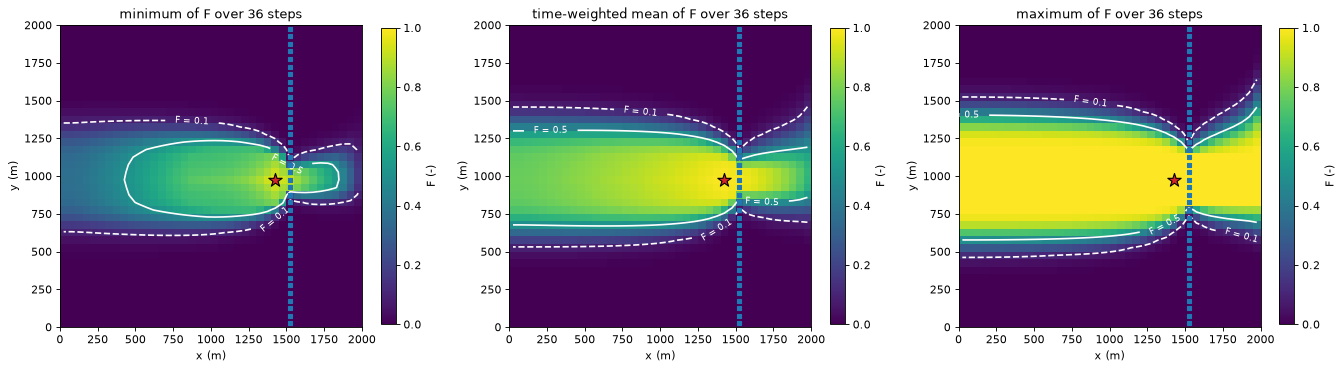

,F > 0.1,F > 0.5
area (km2),,
min F,1.230,0.528
mean F,1.552,1.058
max F,1.840,1.412


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17.0, 4.8))
for ax, values, name in zip(axes, (F_min, F_mean, F_max), ("minimum", "time-weighted mean", "maximum")):
    hbd.plot_cells(
        run.grb_file, stats.template, values, ax=ax, cmap="viridis", vmin=0.0, vmax=1.0,
        title=f"{name} of F over 36 steps", label="F (-)", overlay=False,
    )
    hbd.add_contours(ax, run.grb_file, stats.template, values, (F_OUTLINE, F_CAPTURE), colors="w", linestyles=["--", "-"])
    hbd.overlay_features(ax, run.grb_file, stats.template, packages=("SFR", "WEL"), legend=False)
fig.tight_layout()
plt.show()

area = stats.template.area
zone_areas = pd.DataFrame(
    {f"F > {t}": [area[v > t].sum() / 1e6 for v in (F_min, F_mean, F_max)] for t in (F_OUTLINE, F_CAPTURE)},
    index=["min F", "mean F", "max F"],
)
display(zone_areas.round(3).rename_axis("area (km2)"))

How to read the three maps:

- **Minimum F:** a cell with min $F > 0.5$ is in the capture zone in *every* step. It is the core that never leaves the zone. Its area (0.53 km²) is close to that of the last wet season's zone (0.58 km², section 3).
- **Maximum F:** max $F > 0.1$ is the envelope of every step's conservative outline. A cell outside it never sends more than a tenth of its water to the well in any step.
- **Mean F:** the time-weighted average share. Because $F$ is a fraction of each step's throughflow, the mean $F$ is not the capture zone of the mean flow field. It is a single map of the typical share.

### Always, sometimes, never

`asn` classifies each cell by whether $F > 0.5$ in all steps, some steps or none; `exceedance_count` says in how many.

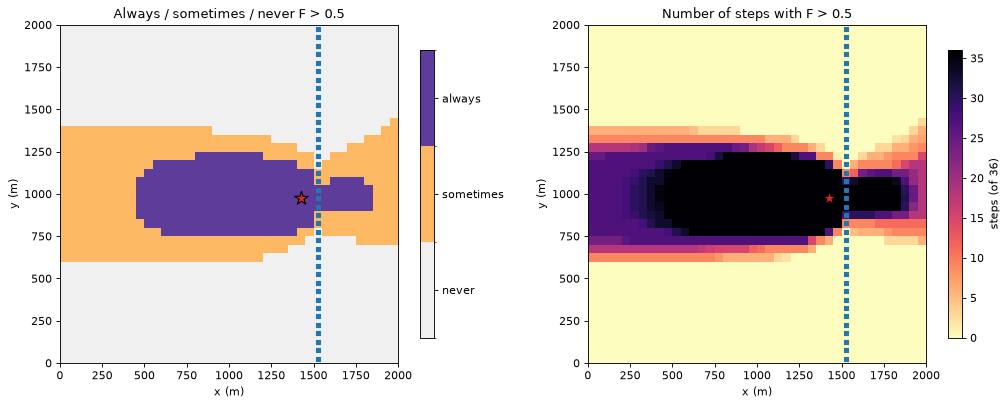

{'always': '0.527 km2', 'sometimes': '0.885 km2', 'never': '2.587 km2'}


In [9]:
asn = stats.stats["asn"]["fraction_through"][WELL]
count = stats.stats["exceedance_count"]["fraction_through"][WELL]
asn_cmap = ListedColormap(["#f0f0f0", "#fdb863", "#5e3c99"])
asn_norm = BoundaryNorm([-0.25, 0.25, 0.75, 1.25], asn_cmap.N)

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.0))
hbd.plot_cells(run.grb_file, stats.template, asn, ax=axes[0], cmap=asn_cmap, norm=asn_norm,
               title=f"Always / sometimes / never F > {F_CAPTURE}", colorbar=False, overlay=False)
bar = plt.colorbar(axes[0].collections[0], ax=axes[0], shrink=0.85, ticks=[0.0, 0.5, 1.0])
bar.ax.set_yticklabels(["never", "sometimes", "always"])
hbd.plot_cells(run.grb_file, stats.template, count.astype(float), ax=axes[1], cmap="magma_r", vmin=0,
               vmax=len(stats.steps), title=f"Number of steps with F > {F_CAPTURE}", label="steps (of 36)",
               overlay=False)
for ax in axes:
    hbd.overlay_features(ax, run.grb_file, stats.template, packages=("SFR", "WEL"), legend=False)
fig.tight_layout()
plt.show()
print({name: f"{area[asn == value].sum() / 1e6:.3f} km2" for value, name in ((1.0, "always"), (0.5, "sometimes"), (0.0, "never"))})

The "sometimes" band is where the zone edge moves with the seasons. The count map grades it. Cells next to the always-zone are captured in most steps. Cells at its outer edge are captured in only a few steps.

### Probability that a cell carries more than 1 m³/d of the well's water

The **volume through** $F_i O_i$ is how much of a cell's flow ends up in the well (tutorial 01). A threshold on it picks out the flow paths that carry a meaningful amount of the well's water, not just a meaningful share of a cell's water. A second run sets `test_output="volume_through"` and `value_range=(1, inf)`. `probability_in_range` is then the time-weighted share of the steps in which at least 1 m³/d of the cell's flow reaches the well.

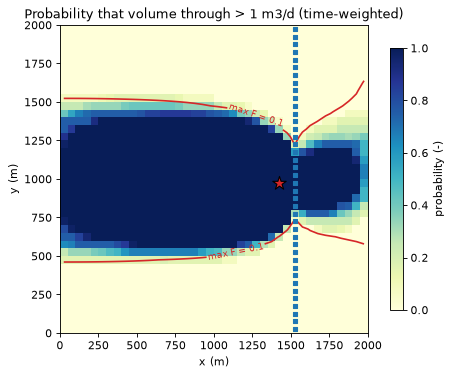

cells with probability 1: 526, between 0 and 1: 241 (0.603 km2; the seasonal band of section 5 is 0.885 km2)
cells with probability > 0 outside the envelope max F > 0.1: 49, largest probability there 0.33, largest max F there 0.099


In [10]:
config_v = gs.TransientConfig(
    steps=SEASONAL_PERIODS, outputs=("volume_through",), test_output="volume_through",
    value_range=(VOLUME_LIMIT, np.inf),
)
stats_v = gs.trace_transient(reader, groups, "backward", config_v)
prob = stats_v.stats["probability_in_range"]["volume_through"][WELL]

ax = hbd.plot_cells(
    run.grb_file, stats_v.template, prob, cmap="YlGnBu", vmin=0.0, vmax=1.0, overlay=False,
    title=f"Probability that volume through > {VOLUME_LIMIT:g} m3/d (time-weighted)", label="probability (-)",
)
hbd.add_contours(ax, run.grb_file, stats.template, F_max, (F_OUTLINE,), colors="tab:red", fmt="max F = %.1f")
hbd.overlay_features(ax, run.grb_file, stats.template, packages=("SFR", "WEL"), legend=False)
plt.show()
between = (prob > 0) & (prob < 1)
print(f"cells with probability 1: {np.sum(prob == 1.0)}, between 0 and 1: {between.sum()} "
      f"({area[between].sum() / 1e6:.3f} km2; the seasonal band of section 5 is {area[asn == 0.5].sum() / 1e6:.3f} km2)")
outside = (prob > 0) & ~(F_max > F_OUTLINE)
print(f"cells with probability > 0 outside the envelope max F > {F_OUTLINE}: {outside.sum()}, "
      f"largest probability there {prob[outside].max():.2f}, largest max F there {F_max[outside].max():.3f}")

In 526 cells, more than 1 m³/d of the well's water passes through in every step. The captured water accumulates along the flow paths towards the well. Even at the west edge, each constant-head cell brings in a few m³/d of regional inflow. The probability falls off at the sides of the zone, where a cell sends just a small share of its water to the well, and east of the stream. The band of intermediate probability (0.603 km²) is smaller than the seasonal band of section 5 (0.885 km²).

Most of the map lies inside the envelope max $F > 0.1$ (red). The exceptions are 49 cells just outside its north and south sides. There, less than a tenth of a cell's flow reaches the well, but that is still more than 1 m³/d in a few steps (probability at most 0.33). The map marks the flow paths that carry a meaningful *volume* of the well's water, not just a meaningful *share* of some cell's water. A higher limit would narrow it to the trunk of the flow system near the well.

## 6. Time weighting vs equal weighting

The mean and `probability_in_range` are weighted averages over the steps. With `weighting="time"` (the default) each step is weighted by its length, so the mean is a **time average**. With `weighting="equal"` every step counts once.

They differ only when the steps have different lengths. The 36 seasonal steps are all 30.4 days, so the two give the same mean. Including the 1-day steady start changes that: time weighting gives it a weight of 1/1097, equal weighting 1/37. The third case, the steady start plus the first wet season (one 1-day step and three 30-day steps), shows how far apart they can be:

In [11]:
cases = {"36 seasonal steps": SEASONAL_PERIODS, "all 37 steps": "all", "steady start + first wet season": [0, 1]}
rows = {}
for name, steps in cases.items():
    means, weight_of_steady = {}, {}
    for weighting in ("time", "equal"):
        cfg = gs.TransientConfig(steps=steps, weighting=weighting)
        result = gs.trace_transient(reader, groups, "backward", cfg)
        means[weighting] = result.stats["mean"]["fraction_through"][WELL]
        is_steady = [ks == (0, 0) for ks in result.steps]
        weight_of_steady[weighting] = result.weights[is_steady].sum() / result.weights.sum()
    rows[name] = {
        **{f"steady-step weight ({w})": v for w, v in weight_of_steady.items()},
        **{f"area mean F > {F_CAPTURE} ({w}, km2)": area[m > F_CAPTURE].sum() / 1e6 for w, m in means.items()},
        "max |mean F time - equal|": np.abs(means["time"] - means["equal"]).max(),
    }
display(pd.DataFrame(rows).T.round(3))

,steady-step weight (time),steady-step weight (equal),"area mean F > 0.5 (time, km2)","area mean F > 0.5 (equal, km2)",max |mean F time - equal|
36 seasonal steps,0.000,0.000,1.058,1.058,0.000
all 37 steps,0.001,0.027,1.058,1.065,0.010
steady start + first wet season,0.011,0.250,0.605,0.865,0.186


- With equal step lengths the choice does not matter.
- Over all 37 steps the 1-day steady step barely matters either way (mean $F$ differs by at most 0.01).
- A short step counted as a full one can pull the mean a long way: in the last case the 1-day steady step, which describes a different flow regime, makes up a quarter of the equal-weighted mean, and the area with mean $F > 0.5$ grows from 0.605 to 0.865 km².

**Use time weighting** when the steps are intervals of one simulation, which is nearly always the case: then "mean" and "probability" mean "share of the time". In particular, models whose step lengths grow within a period (TSMULT > 1) need time weighting. **Use equal weighting** when each step stands for a *scenario* rather than a duration, for example one representative step taken from each of several stress periods that are meant to count equally. Either way, leave out spin-up periods that do not belong to the period being described (`steps=`).

## 7. One way to combine the maps

The statistics can be combined into nested zones. This section shows one way to do it, as an example of using the maps together. It is not a recommendation for protection zones: the thresholds, and how a zone is used, are choices for each study.

- **Inner zone: always captured.** Cells with $F > 0.5$ in every step (`asn == 1`). This is the core that feeds the well whatever the season.
- **Seasonal zone: sometimes captured.** Cells with `asn == 0.5`, part of the capture zone in some steps but not all. The exceedance count, or `probability_in_range` on $F$, ranks the cells within it.
- **Outer envelope.** Cells with max $F > 0.1$: every cell that sends more than a tenth of its water to the well in *some* step. It holds the inner zone, the seasonal zone and a **ring** of cells where $F$ stays at or below 0.5 in every step but exceeds 0.1 in at least one. The envelope covers both the seasonal movement of the zone and the smearing of the edge by full mixing ([tutorial 11](../11_numerical_dispersion/11_numerical_dispersion.ipynb)).
- **Ranking inside the zones.** The probability that the volume through exceeds a limit picks out the main flow paths to the well. The volume from by source (section 4) says which sources matter in which season.

The table under the map gives the area of each part. The inner zone, the seasonal zone and the ring do not overlap, and together they make up the outer envelope.

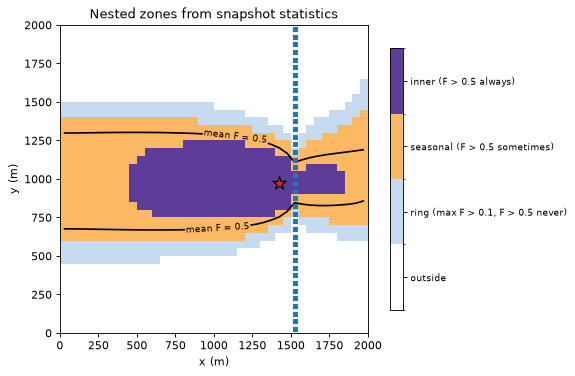

,area (km2)
inner: F > 0.5 in every step,0.528
seasonal: F > 0.5 in some steps,0.885
"ring: max F > 0.1, F > 0.5 in no step",0.428
outer envelope: max F > 0.1 (all three),1.840
outside the envelope,2.160


In [12]:
envelope = F_max > F_OUTLINE  # outer envelope: inner + seasonal + ring
classes = np.zeros(stats.template.n_cells)
classes[envelope] = 1  # ring: in the envelope, outside the inner and seasonal zones
classes[asn == 0.5] = 2  # seasonal zone
classes[asn == 1.0] = 3  # inner zone
zone_names = ["outside", f"ring (max F > {F_OUTLINE}, F > {F_CAPTURE} never)", f"seasonal (F > {F_CAPTURE} sometimes)",
              f"inner (F > {F_CAPTURE} always)"]
zone_cmap = ListedColormap(["#ffffff", "#c6dbef", "#fdb863", "#5e3c99"])

ax = hbd.plot_cells(
    run.grb_file, stats.template, classes, cmap=zone_cmap, norm=BoundaryNorm(np.arange(-0.5, 4.0), 4),
    title="Nested zones from snapshot statistics", colorbar=False, overlay=False,
)
bar = plt.colorbar(ax.collections[0], ax=ax, shrink=0.85, ticks=range(4))
bar.ax.set_yticklabels(zone_names, fontsize=8)
hbd.add_contours(ax, run.grb_file, stats.template, F_mean, (F_CAPTURE,), colors="k", fmt="mean F = %.1f")
hbd.overlay_features(ax, run.grb_file, stats.template, packages=("SFR", "WEL"), legend=False)
plt.show()
zone_areas = {
    f"inner: F > {F_CAPTURE} in every step": area[classes == 3].sum(),
    f"seasonal: F > {F_CAPTURE} in some steps": area[classes == 2].sum(),
    f"ring: max F > {F_OUTLINE}, F > {F_CAPTURE} in no step": area[classes == 1].sum(),
    f"outer envelope: max F > {F_OUTLINE} (all three)": area[envelope].sum(),
    "outside the envelope": area[~envelope].sum(),
}
display((pd.Series(zone_areas, name="area (km2)") / 1e6).round(3).to_frame())

The limits of section 2 apply to these zones. They describe where the *steady* capture zone of each step lies. They do not say how long water takes to arrive (tutorial 06 adds travel time). They do not say where water released from storage first entered the aquifer (tutorial 08 tracks it). The envelope includes the zone of every step. The storage limit matters most when a large share of the well's water comes from storage, as in the dry season here (53 %, section 4).

### Export

The statistics export like single-step results: `gs.export.to_netcdf` writes every statistic (`<output>_<statistic>`) plus a `time` dimension with the analysed steps, their weights and the well's inflow per step. `gs.export.to_geopackage` writes the statistics as columns of the cell polygons for GIS (tutorial 04).

In [13]:
nc_path = gs.export.to_netcdf(WORK / "snapshot_statistics.nc", stats)
with xr.open_dataset(nc_path) as ds:
    print(f"{nc_path.name}: dims {dict(ds.sizes)}")
    print("variables:", ", ".join(ds.data_vars))
    print("well inflow per step (m3/d):", np.round(ds["group_inflow"].sel(group=WELL).values[:6], 1), "...")

snapshot_statistics.nc: dims {'layer': 1, 'row': 40, 'col': 40, 'time': 36, 'group': 1}
variables: active, area, step_weight, group_inflow, fraction_through_min, volume_through_min, fraction_through_max, volume_through_max, fraction_through_mean, volume_through_mean, fraction_through_asn, fraction_through_exceedance_count
well inflow per step (m3/d): [640. 640. 640. 800. 800. 800.] ...


## 8. Sanity check: streaming statistics equal a brute-force calculation

`trace_transient` never holds all steps in memory. The loop of section 4 kept every step's $F$, so we can recompute the statistics with numpy over the stored stack and compare.

In [14]:
stack = np.array([f_series[ks] for ks in stats.steps])  # (36 steps, cells)
weights = stats.weights / stats.weights.sum()
np.testing.assert_allclose(F_min, stack.min(axis=0), rtol=0, atol=1e-14)
np.testing.assert_allclose(F_max, stack.max(axis=0), rtol=0, atol=1e-14)
np.testing.assert_allclose(F_mean, weights @ stack, rtol=1e-12, atol=1e-14)
n_above = (stack > F_CAPTURE).sum(axis=0)
np.testing.assert_array_equal(count, n_above)
np.testing.assert_array_equal(asn, np.select([n_above == 0, n_above == len(stack)], [0.0, 1.0], 0.5))
assert (by_step[list(SOURCES)].sum(axis=1) - by_step["pumping"]).abs().max() < 1e-6
print("streaming statistics match the stored steps; every snapshot closes")
print(f"notebook run time: {time.perf_counter() - START:.0f} s")

streaming statistics match the stored steps; every snapshot closes
notebook run time: 2 s


## Key points

- A transient model is traced as a series of **snapshots**: each time step's flows are treated as steady. Storage release is a source and storage gain a sink, like any other external term.
- Snapshots show how the capture zone **moves with the seasons**, cheaply and from the budget file alone. They have **no travel lag**, and they label water released from storage as "storage" rather than by its original source. Tutorial 08 removes both limits with true transient tracking.
- `gs.trace_transient` summarises any per-cell output over the steps with streaming statistics: **min, max and mean**, **always/sometimes/never** above a threshold, the **exceedance count** and the **probability within a range** (here, of carrying more than 1 m³/d of the well's water).
- Means and probabilities are **time-weighted** by default. Equal weighting only differs when step lengths differ. It is meant for steps that stand for scenarios. Leave spin-up periods out with `steps=`.
- The maps can be combined into nested zones: the always-captured core, the sometimes-captured seasonal band and the max-$F$ envelope. This is one way to combine them, not a recommendation for protection zones. The volume through and the volume from by source rank the cells within the zones.

## Next

[06 · Travel time](../06_travel_time/06_travel_time.ipynb): how old the water reaching the well is, from the same matrix, and how it compares with MF6 particle tracking.